# Chapitre 2 - Exercices 2.1 à 2.5

Ce notebook traite les cinq premiers exercices du chapitre 2 :

- **2.1** : classer au plus grand $\hat y_k$ revient à choisir la cible la plus proche ;
- **2.2** : calcul de la frontière de Bayes de la simulation mixture ;
- **2.3** : distance médiane au plus proche voisin, éq. (2.24) ;
- **2.4** : en grande dimension, les points tests sont « au bord » de l'échantillon ;
- **2.5** : erreur de prédiction du modèle linéaire, éq. (2.27) et (2.28).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, special
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl.plotting import decision_grid
from esl import datasets
from esl import ch02_supervise as c2

set_style()
rng = np.random.RandomState(0)

## Exercice 2.1 : Plus grande composante et cible la plus proche

**Énoncé (reformulé).** On a $K$ classes ; la classe $k$ est associée à une **cible**
$t_k \in \mathbb R^K$, vecteur dont toutes les composantes sont nulles sauf la $k$-ième
qui vaut 1. Pour une prédiction $\hat y \in \mathbb R^K$ dont les composantes ont pour
somme 1, montrer que classer selon la plus grande composante de $\hat y$ revient à
choisir la cible la plus proche, c'est-à-dire la classe $k$ minimisant $\|t_k - \hat y\|$.

**Contexte.** C'est la situation de la régression sur variables indicatrices : on code
chaque classe par le vecteur $t_k$, on ajuste chacune des $K$ coordonnées par
moindres carrés, et l'on obtient pour un nouveau $x$ un vecteur $\hat y(x)$. Lorsque le
modèle contient une constante, les composantes de $\hat y$ somment à 1 (chapitre 4).

**Solution.** Développons le carré de la distance (le minimum de $\|t_k - \hat y\|$ et
celui de $\|t_k - \hat y\|^2$ sont atteints au même $k$, car $u \mapsto u^2$ est
croissante sur $\mathbb R_+$) :
$$\|t_k - \hat y\|^2 = \|t_k\|^2 - 2\,t_k^T\hat y + \|\hat y\|^2.$$
Or $\|t_k\|^2 = 1$ (une seule composante non nulle, égale à 1) et $t_k^T\hat y = \hat y_k$
(le produit scalaire avec $t_k$ extrait la $k$-ième composante). Donc
$$\|t_k - \hat y\|^2 = 1 - 2\hat y_k + \|\hat y\|^2.$$

Le terme $1 + \|\hat y\|^2$ ne dépend pas de $k$. Par conséquent
$$\arg\min_k \|t_k - \hat y\|^2 = \arg\min_k\,(-2\hat y_k) = \arg\max_k \hat y_k. \qquad\blacksquare$$

> **Remarque.** L'hypothèse « les $\hat y_k$ somment à 1 » n'a en fait **pas servi** :
> l'équivalence est vraie pour tout $\hat y \in \mathbb R^K$. Elle sert seulement à
> interpréter $\hat y$ comme une estimation des probabilités des classes.

**Vérification numérique** sur 10 000 vecteurs aléatoires de $\mathbb R^5$, normalisés
(somme 1) ou non.

In [2]:
K = 5
T = np.eye(K)                       # les cibles t_k sont les lignes de l'identité
Y = rng.normal(size=(10000, K))
for name, Yhat in [("quelconques", Y), ("somme = 1", Y - Y.mean(1, keepdims=True) + 1 / K)]:
    dist = ((Yhat[:, None, :] - T[None, :, :]) ** 2).sum(-1)    # (10000, K)
    agree = np.mean(dist.argmin(1) == Yhat.argmax(1))
    print("%-12s : accord argmin distance / argmax composante = %.4f" % (name, agree))

quelconques  : accord argmin distance / argmax composante = 1.0000
somme = 1    : accord argmin distance / argmax composante = 1.0000


Visualisation pour $K = 3$ sur le plan $\{\hat y_1 + \hat y_2 + \hat y_3 = 1\}$ (paramétré
par $(\hat y_1, \hat y_2)$) : les régions « cible la plus proche » et « plus grande
composante » coïncident.

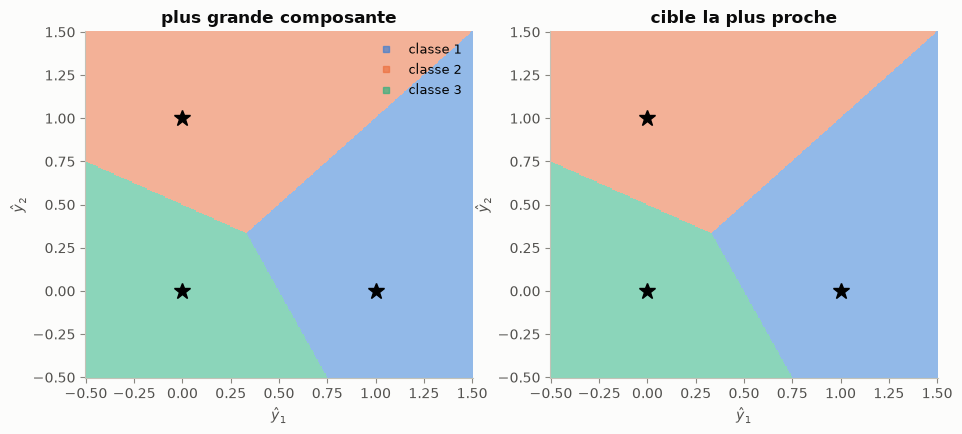

In [3]:
u, v, P = decision_grid((-0.5, 1.5), (-0.5, 1.5), n=300)
Yh = np.c_[P, 1 - P.sum(1)]
lab_max = Yh.argmax(1).reshape(u.shape)
lab_dist = ((Yh[:, None, :] - np.eye(3)[None]) ** 2).sum(-1).argmin(1).reshape(u.shape)
from matplotlib.colors import ListedColormap
cm3 = ListedColormap(COLORS[:3])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, lab, name in zip(axes, [lab_max, lab_dist], ["plus grande composante", "cible la plus proche"]):
    ax.pcolormesh(u, v, lab, cmap=cm3, shading="auto", alpha=0.5)
    ax.plot([1, 0, 0], [0, 1, 0], "k*", ms=12)
    ax.set_xlabel("$\\hat y_1$")
    ax.set_ylabel("$\\hat y_2$")
    ax.set_title(name)
    ax.grid(False)
for k in range(3):
    axes[0].plot([], [], "s", color=COLORS[k], alpha=0.6, label="classe %d" % (k + 1))
axes[0].legend(loc="upper right")
plt.show()

> **À retenir.** $\|t_k - \hat y\|^2 = 1 - 2\hat y_k + \|\hat y\|^2$ : choisir la cible la
> plus proche, c'est choisir la plus grande composante de $\hat y$.

## Exercice 2.2 : Calcul de la frontière de Bayes de la simulation mixture

**Énoncé (reformulé).** Expliquer comment calculer la frontière de décision de Bayes
de l'exemple simulé de la figure 2.5.

**Rappels.** Le modèle génératif (section 2.3.3) est :

- classe BLEU : $X \sim \frac1{10}\sum_{k=1}^{10}\mathcal N(m_k, \mathbf I/5)$, centres $m_k$ tirés selon $\mathcal N((1,0)^T, \mathbf I)$ ;
- classe ORANGE : $X \sim \frac1{10}\sum_{k=1}^{10}\mathcal N(n_k, \mathbf I/5)$, centres $n_k$ tirés selon $\mathcal N((0,1)^T, \mathbf I)$ ;
- les deux classes ont la même probabilité a priori $\pi_B = \pi_O = 1/2$.

Le classifieur de Bayes (éq. (2.23)) choisit la classe de plus grande probabilité a
posteriori ; la frontière est l'ensemble des $x$ où les deux probabilités a posteriori
sont égales.

**Étape 1 : densités des classes.** La densité de $\mathcal N(m, \sigma^2\mathbf I_2)$, avec $\sigma^2 = 1/5$, est
$$\varphi_m(x) = \frac{1}{2\pi\sigma^2}\exp\Big(-\frac{\|x - m\|^2}{2\sigma^2}\Big) = \frac{5}{2\pi}\exp\Big(-\frac52\|x - m\|^2\Big).$$
Donc $p_B(x) = \frac1{10}\sum_k\varphi_{m_k}(x)$ et $p_O(x) = \frac1{10}\sum_k\varphi_{n_k}(x)$.

**Étape 2 : probabilités a posteriori.** Par la formule de Bayes,
$$\Pr(\text{ORANGE}\mid X = x) = \frac{\pi_O\,p_O(x)}{\pi_B\,p_B(x) + \pi_O\,p_O(x)} = \frac{p_O(x)}{p_B(x) + p_O(x)}.$$

**Étape 3 : la frontière.** $\Pr(\text{ORANGE}\mid x) = \Pr(\text{BLEU}\mid x)$ équivaut à
$p_O(x) = p_B(x)$, c'est-à-dire (en simplifiant les constantes communes $\frac{1}{10}\cdot\frac{5}{2\pi}$) :
$$\sum_{k=1}^{10}\exp\Big(-\frac52\|x - n_k\|^2\Big) = \sum_{k=1}^{10}\exp\Big(-\frac52\|x - m_k\|^2\Big).$$
C'est une courbe implicite $\{x : \delta(x) = 0\}$, avec
$\delta(x) = \log\sum_k e^{-\frac52\|x-n_k\|^2} - \log\sum_k e^{-\frac52\|x-m_k\|^2}$. Elle n'a
pas d'expression explicite, mais se calcule numériquement.

**Étape 4 : calcul numérique.** Deux méthodes :

1. évaluer $\delta$ sur une grille fine et tracer la **ligne de niveau 0** ;
2. pour chaque abscisse $x_1$ fixée, rechercher les **racines** de $x_2 \mapsto \delta(x_1, x_2)$ :
   on repère les changements de signe sur une grille, puis on affine chacun par
   dichotomie (méthode de Brent).

Nous utilisons les centres exacts fournis avec les données du livre.

In [4]:
mix = datasets.load_mixture_example()
means = mix["means"]
m_blue, m_orange = means[:10], means[10:]


def delta(P):
    """log p_O(x) - log p_B(x) (constantes communes simplifiées)."""
    P = np.atleast_2d(P)
    a = -2.5 * c2.squared_distances(P, m_orange)
    b = -2.5 * c2.squared_distances(P, m_blue)
    return special.logsumexp(a, axis=1) - special.logsumexp(b, axis=1)


xx, yy, grid = decision_grid((-2.6, 4.2), (-2.0, 2.9), n=300)
D = delta(grid).reshape(xx.shape)

In [5]:
from scipy.optimize import brentq

roots = []
x2_scan = np.linspace(-2.0, 2.9, 200)
for x1 in np.linspace(-2.6, 4.2, 70):
    vals = delta(np.c_[np.full_like(x2_scan, x1), x2_scan])
    for j in np.flatnonzero(np.sign(vals[:-1]) != np.sign(vals[1:])):
        f1 = lambda t: delta(np.array([[x1, t]]))[0]
        roots.append((x1, brentq(f1, x2_scan[j], x2_scan[j + 1])))
roots = np.array(roots)
print("nombre de points de frontière trouvés :", len(roots))
print("max |delta| aux racines :", np.abs(delta(roots)).max())

nombre de points de frontière trouvés : 67
max |delta| aux racines : 8.643641358219156e-13


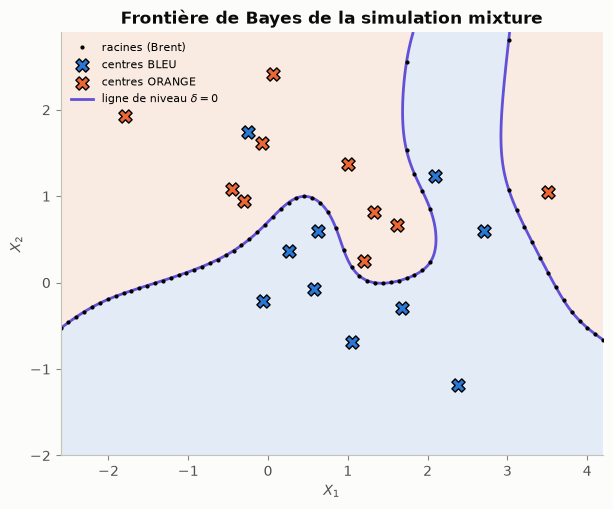

In [6]:
fig, ax = plt.subplots(figsize=(7, 5.5))
X, g = mix["x"], mix["y"]
ax.contourf(xx, yy, (D > 0).astype(float), levels=[-0.5, 0.5, 1.5], cmap=TWO_CLASS, alpha=0.12)
ax.contour(xx, yy, D, levels=[0], colors=COLORS[6], linewidths=2)
ax.plot(roots[:, 0], roots[:, 1], "k.", ms=4, label="racines (Brent)")
ax.scatter(m_blue[:, 0], m_blue[:, 1], marker="X", s=90, color=BLUE, edgecolors="k", label="centres BLEU")
ax.scatter(m_orange[:, 0], m_orange[:, 1], marker="X", s=90, color=ORANGE, edgecolors="k", label="centres ORANGE")
ax.plot([], [], color=COLORS[6], label="ligne de niveau $\\delta = 0$")
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.grid(False)
ax.set_title("Frontière de Bayes de la simulation mixture")
ax.legend(loc="upper left", fontsize=8)
plt.show()

Les deux méthodes concordent. Vérifions aussi que nos probabilités a posteriori
coïncident avec celles fournies par les auteurs (`prob`), et estimons le **taux d'erreur
de Bayes** sur un grand échantillon simulé.

In [7]:
post = 1 / (1 + np.exp(-delta(mix["xnew"])))   # p_O/(p_B+p_O) = 1/(1+exp(-delta))
print("écart max avec les probabilités du livre :", np.abs(post - mix["prob"]).max())
Xt, gt = c2.sample_mixture(means, 50000, rng)
print("taux d'erreur de Bayes (100 000 points) : %.4f" % c2.error_rate(gt, (delta(Xt) > 0).astype(int)))

écart max avec les probabilités du livre : 4.218847493575595e-15


taux d'erreur de Bayes (100 000 points) : 0.2081


> **Remarque.** Ce calcul n'est possible que parce que l'on **connaît** le modèle
> génératif (centres, variance, probabilités a priori). En pratique, ces quantités sont
> inconnues ; on pourrait les estimer (mélanges de gaussiennes, chapitres 6, 8 et 12),
> ce qui donne un classifieur « bayésien empirique ».

> **À retenir.** Avec des priors égaux, la frontière de Bayes est $\{x : p_O(x) = p_B(x)\}$ ;
> ici $\sum_k e^{-\frac52\|x - n_k\|^2} = \sum_k e^{-\frac52\|x - m_k\|^2}$, à calculer
> numériquement (ligne de niveau ou recherche de racines).

## Exercice 2.3 : Distance médiane au plus proche voisin (éq. (2.24))

**Énoncé (reformulé).** Établir l'équation (2.24) : si $N$ points sont uniformément et
indépendamment répartis dans la boule unité de $\mathbb R^p$, la distance médiane de
l'origine au point le plus proche vaut
$$d(p, N) = \Big(1 - \big(\tfrac12\big)^{1/N}\Big)^{1/p}.$$

**Rappels.** Le volume de la boule de rayon $r$ dans $\mathbb R^p$ vaut $v_p r^p$, où
$v_p$ est le volume de la boule unité. La **médiane** d'une variable aléatoire continue
$D$ est le réel $m$ tel que $\Pr(D \le m) = \frac12$.

**Étape 1 : loi de la norme d'un point.** Pour $X$ uniforme dans la boule unité et
$0 \le r \le 1$,
$$\Pr(\|X\| \le r) = \frac{\text{volume de la boule de rayon } r}{\text{volume de la boule unité}} = \frac{v_p r^p}{v_p} = r^p.$$

**Étape 2 : loi du minimum.** Notons $D = \min_{1\le i\le N}\|x_i\|$. Le minimum dépasse $r$
si et seulement si **tous** les points dépassent $r$ ; par indépendance,
$$\Pr(D > r) = \prod_{i=1}^N\Pr(\|x_i\| > r) = (1 - r^p)^N.$$

**Étape 3 : la médiane.** On résout $\Pr(D > r) = \frac12$ :
$$(1 - r^p)^N = \tfrac12 \iff 1 - r^p = \big(\tfrac12\big)^{1/N} \iff r = \Big(1 - \big(\tfrac12\big)^{1/N}\Big)^{1/p}. \qquad\blacksquare$$
Pour $N = 500$, $p = 10$ : $d \approx 0{,}52$.

**Bonus : la distance moyenne.** Pour une variable positive, $E(D) = \int_0^\infty\Pr(D > r)\,dr$. Ici
$$E(D) = \int_0^1 (1 - r^p)^N dr \overset{u = r^p}{=} \frac1p\int_0^1 u^{1/p - 1}(1-u)^N du = \frac1p\,B\Big(\frac1p, N+1\Big) = \frac{\Gamma(1 + 1/p)\,\Gamma(N+1)}{\Gamma(N + 1 + 1/p)},$$
où $B$ est la fonction bêta d'Euler, $B(a,b) = \int_0^1u^{a-1}(1-u)^{b-1}du = \Gamma(a)\Gamma(b)/\Gamma(a+b)$.
C'est l'« expression plus compliquée » évoquée par le livre.

**Vérification numérique.** On simule des points uniformes dans la boule
(`c2.sample_unit_ball` : direction gaussienne normalisée, rayon $U^{1/p}$, ce qui donne
bien $\Pr(\|X\|\le r) = \Pr(U \le r^p) = r^p$).

In [8]:
def mean_nn_distance(p, N):
    return np.exp(special.gammaln(1 + 1 / p) + special.gammaln(N + 1) - special.gammaln(N + 1 + 1 / p))


N = 500
rows = []
for p in [1, 2, 3, 5, 10]:
    D_sim = np.array([np.linalg.norm(c2.sample_unit_ball(N, p, rng), axis=1).min() for _ in range(2000)])
    rows.append((p, c2.median_nn_distance(p, N), np.median(D_sim), mean_nn_distance(p, N), D_sim.mean()))
print(" p | médiane (2.24) | médiane simulée | moyenne (formule) | moyenne simulée")
for r in rows:
    print("%2d | %14.4f | %15.4f | %17.4f | %15.4f" % r)

 p | médiane (2.24) | médiane simulée | moyenne (formule) | moyenne simulée
 1 |         0.0014 |          0.0014 |            0.0020 |          0.0020
 2 |         0.0372 |          0.0370 |            0.0396 |          0.0395
 3 |         0.1115 |          0.1108 |            0.1125 |          0.1131
 5 |         0.2681 |          0.2681 |            0.2649 |          0.2642
10 |         0.5178 |          0.5175 |            0.5110 |          0.5086


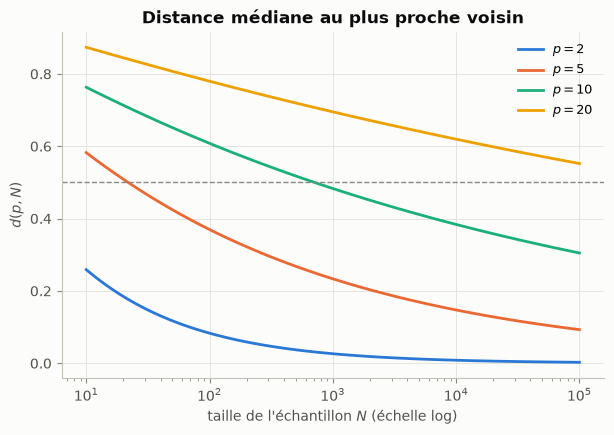

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
Ns = np.logspace(1, 5, 100)
for j, p in enumerate([2, 5, 10, 20]):
    ax.plot(Ns, c2.median_nn_distance(p, Ns), color=COLORS[j], label="$p = %d$" % p)
ax.axhline(0.5, color=GRAY, ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("taille de l'échantillon $N$ (échelle log)")
ax.set_ylabel("$d(p, N)$")
ax.set_title("Distance médiane au plus proche voisin")
ax.legend()
plt.show()

Pour $p = 20$, même avec $N = 100\,000$ points, le plus proche voisin de l'origine reste
en médiane à plus de la moitié du rayon : il faudrait un $N$ astronomique pour qu'il se
rapproche.

> **À retenir.** $\Pr(\min_i\|x_i\| > r) = (1 - r^p)^N$ ; la médiane
> $(1 - 2^{-1/N})^{1/p}$ ne décroît que très lentement avec $N$ quand $p$ est grand.

## Exercice 2.4 : En grande dimension, les points tests sont au bord

**Énoncé (reformulé).** L'effet de bord n'est pas propre aux lois uniformes sur un
domaine borné. Soit des entrées $x_1, \dots, x_N$ i.i.d. de loi $\mathcal N(0, \mathbf I_p)$ ;
le carré de la distance d'un point à l'origine suit une loi $\chi^2_p$, de moyenne $p$.
Soit $x_0$ un point de prédiction de même loi, indépendant, et $a = x_0/\|x_0\|$ le
vecteur unitaire associé. On pose $z_i = a^Tx_i$ (projection du $i$-ème point
d'apprentissage sur la direction $a$).

Montrer que les $z_i$ sont de loi $\mathcal N(0,1)$, de distance quadratique moyenne à
l'origine égale à 1, alors que le point cible a une distance quadratique moyenne $p$.
Pour $p = 10$, un point test est donc à environ 3,1 écarts-types de l'origine, tandis
que les points d'apprentissage sont en moyenne à un écart-type le long de $a$ : la
plupart des points de prédiction se trouvent « au bord » de l'échantillon.

**Rappels.**

- Si $x \sim \mathcal N(0, \Sigma)$ dans $\mathbb R^p$ et $a \in \mathbb R^p$ est fixé, alors
  $a^Tx \sim \mathcal N(0, a^T\Sigma a)$ (une combinaison linéaire d'un vecteur gaussien
  est gaussienne).
- Si $x_{01}, \dots, x_{0p}$ sont i.i.d. $\mathcal N(0,1)$, alors $\sum_j x_{0j}^2 \sim \chi^2_p$,
  de moyenne $\sum_j E(x_{0j}^2) = p$.

**Solution.**

*Loi des $z_i$.* Conditionnellement à $x_0$, le vecteur $a$ est fixé, de norme 1, et
$x_i$ est indépendant de $x_0$, donc toujours de loi $\mathcal N(0, \mathbf I_p)$. D'après
le rappel, $z_i \mid x_0 \sim \mathcal N(0, a^T\mathbf I_pa) = \mathcal N(0, \|a\|^2) = \mathcal N(0,1)$.
Cette loi conditionnelle **ne dépend pas** de $x_0$ : c'est donc aussi la loi (non
conditionnelle) de $z_i$. En particulier $E(z_i^2) = \mathrm{Var}(z_i) = 1$.

*Distance du point cible.* $\|x_0\|^2 = \sum_{j=1}^p x_{0j}^2 \sim \chi^2_p$, d'espérance $p$.
Le point cible, projeté sur sa propre direction $a$, se trouve en $a^Tx_0 = \|x_0\|$.

*Application numérique.* Pour $p = 10$, $\sqrt{E\|x_0\|^2} = \sqrt{10} \approx 3{,}16$ ; plus
précisément $E\|x_0\| = \sqrt2\,\Gamma(\frac{p+1}2)/\Gamma(\frac p2) \approx 3{,}08$ (moyenne de la loi du
$\chi$). Le point test est donc à environ 3,1 écarts-types de l'origine selon $a$, alors
que les projections des points d'apprentissage sont de loi $\mathcal N(0,1)$.

In [ ]:
p, N = 10, 500
print("sqrt(p) = %.3f ; E||x0|| = %.3f" % (np.sqrt(p),
      np.sqrt(2) * np.exp(special.gammaln((p + 1) / 2) - special.gammaln(p / 2))))
reps = 2000
z_all, r0, frac_beyond = [], [], []
for _ in range(reps):
    Xtr = rng.normal(size=(N, p))
    x0 = rng.normal(size=p)
    a = x0 / np.linalg.norm(x0)
    z = Xtr @ a
    z_all.append(z[:20])
    r0.append(np.linalg.norm(x0))
    frac_beyond.append(np.mean(z >= np.linalg.norm(x0)))
z_all, r0 = np.concatenate(z_all), np.array(r0)
print("moyenne et variance des z_i : %.3f, %.3f" % (z_all.mean(), z_all.var()))
print("E||x0||^2 simulée : %.3f (théorie p = %d)" % (np.mean(r0 ** 2), p))
print("proportion moyenne de points d'apprentissage au-delà de x0 selon a : %.4f" % np.mean(frac_beyond))

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
t = np.linspace(-4, 6, 400)
ax.hist(z_all, bins=60, density=True, color=BLUE, alpha=0.55, label="projections $z_i = a^Tx_i$")
ax.plot(t, stats.norm.pdf(t), color=BLUE, lw=1.5, label="densité $\\mathcal{N}(0,1)$")
ax.hist(r0, bins=40, density=True, color=ORANGE, alpha=0.55, label="position du point test $\\|x_0\\|$")
ax.plot(t[t > 0], stats.chi.pdf(t[t > 0], p), color=ORANGE, lw=1.5, label="densité du $\\chi_{10}$")
ax.set_xlabel("coordonnée le long de la direction $a$")
ax.set_ylabel("densité")
ax.set_title("p = 10 : le point test est au bord de l'échantillon")
ax.legend()
plt.show()

Selon la direction qui pointe vers lui, le point test est presque toujours plus loin
que **tous** les points d'apprentissage (en moyenne, environ 0,5 % seulement des
points sont au-delà) : prédire en $x_0$ revient à **extrapoler**. Le phénomène
s'aggrave avec $p$, puisque $\|x_0\| \approx \sqrt p$ alors que les $z_i$ restent $\mathcal N(0,1)$.